In [15]:
# Core libraries
from pathlib import Path
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# 08 — Predicting High-Reach Steam Games

## Business Objective

The objective of this analysis is to test whether
a game's product and market-positioning characteristics
can help predict whether it reaches a large audience
on Steam.

### Business Question

**Can product characteristics help predict whether a
Steam game reaches at least 100,000 estimated owners?**

A game is classified as high reach when the lower bound
of its estimated owner range is at least 100,000.

Only characteristics describing the product and its
market positioning are used as predictors.

Performance variables such as reviews, satisfaction,
peak concurrent users and playtime are excluded to
avoid data leakage.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

project_root = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

data_path = (
    project_root
    / "data/processed/games_cleaned_march2025.csv"
)

df_model = pd.read_csv(data_path)

print("Dataset shape:", df_model.shape)

Dataset shape: (94948, 48)


## 1. Target Definition

The prediction target is based on estimated player reach.

Games with an estimated owner lower bound of at least
100,000 are classified as **high reach**.

Games without an available owner estimate are excluded
from the supervised learning sample because their target
cannot be determined.

In [2]:
# Keep only games with available owner estimates

df_supervised = df_model[
    df_model["owners_lower"].notna()
].copy()

# Create binary target

df_supervised["high_reach"] = (
    df_supervised["owners_lower"] >= 100_000
).astype(int)

print("Games available for modeling:", len(df_supervised))

print("\nTarget distribution:")
print(df_supervised["high_reach"].value_counts())

print("\nTarget distribution (%):")
print(
    df_supervised["high_reach"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Games available for modeling: 81292

Target distribution:
high_reach
0    73629
1     7663
Name: count, dtype: int64

Target distribution (%):
high_reach
0    90.57
1     9.43
Name: proportion, dtype: float64


## 2. Predictor Selection

The predictors are restricted to product and
market-positioning characteristics.

Variables that directly reflect market performance,
such as reviews, owner estimates, concurrent users
and playtime, are excluded to avoid data leakage.

Game age and accumulated DLC count are also excluded
from the predictive model because they reflect
post-release product maturity rather than characteristics
that could reasonably be considered around launch.

The model therefore focuses on:

- price,
- desktop platform availability,
- major genres,
- and Early Access positioning.

In [3]:
import ast

def parse_list(value):
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []


df_supervised["genres_list"] = (
    df_supervised["genres"].apply(parse_list)
)

selected_genres = [
    "Indie",
    "Casual",
    "Action",
    "Adventure",
    "Simulation",
    "Strategy",
    "RPG"
]

for genre in selected_genres:
    column_name = "genre_" + genre.lower().replace(" ", "_")

    df_supervised[column_name] = (
        df_supervised["genres_list"]
        .apply(lambda genres: int(genre in genres))
    )

df_supervised["early_access"] = (
    df_supervised["genres_list"]
    .apply(lambda genres: int("Early Access" in genres))
)

df_supervised["platform_count"] = (
    df_supervised["windows"].astype(int)
    + df_supervised["mac"].astype(int)
    + df_supervised["linux"].astype(int)
)

df_supervised["log_price"] = np.log1p(
    df_supervised["price"]
)

In [4]:
feature_columns = [
    "log_price",
    "platform_count",
    "genre_indie",
    "genre_casual",
    "genre_action",
    "genre_adventure",
    "genre_simulation",
    "genre_strategy",
    "genre_rpg",
    "early_access"
]

X = df_supervised[feature_columns].copy()
y = df_supervised["high_reach"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values in X:", X.isna().sum().sum())

display(X.head())

X shape: (81292, 10)
y shape: (81292,)
Missing values in X: 0


,log_price,platform_count,genre_indie,genre_casual,genre_action,genre_adventure,genre_simulation,genre_strategy,genre_rpg,early_access
0,0.000000,2,0,0,1,0,0,0,0,0
1,0.000000,1,0,0,1,1,0,0,0,0
2,0.000000,3,0,0,1,0,0,1,0,0
3,0.000000,1,0,0,1,1,0,0,0,0
4,3.044046,1,0,0,1,0,0,0,0,0


## 3. Train-Test Split and Scaling

The dataset is divided into training and test sets.

Because high-reach games represent only 9.43% of the
modeling sample, stratified sampling is used to preserve
the class distribution in both sets.

Scaling is fitted only on the training data to avoid
information leakage from the test set.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nHigh-reach share in training:")
print(round(y_train.mean() * 100, 2), "%")

print("\nHigh-reach share in test:")
print(round(y_test.mean() * 100, 2), "%")

Training set: (65033, 10)
Test set: (16259, 10)

High-reach share in training:
9.43 %

High-reach share in test:
9.43 %


In [6]:
from sklearn.preprocessing import StandardScaler

numeric_features = [
    "log_price",
    "platform_count"
]

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler = StandardScaler()

X_train_scaled[numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)

X_test_scaled[numeric_features] = scaler.transform(
    X_test[numeric_features]
)

display(
    X_train_scaled[numeric_features]
    .describe()
    .round(2)
)

,log_price,platform_count
count,65033.00,65033.00
mean,0.00,-0.00
std,1.00,1.00
min,-1.85,-0.51
25%,-0.69,-0.51
50%,0.05,-0.51
75%,0.70,-0.51
max,5.49,2.51


## 4. Logistic Regression Baseline

A Logistic Regression model is used as an interpretable
baseline classifier.

Because high-reach games represent only 9.43% of the
modeling sample, the classes are strongly imbalanced.

The model therefore uses balanced class weights so that
errors on the minority high-reach class receive greater
importance during training.

Model performance is evaluated on the held-out test set
using precision, recall, F1-score and ROC-AUC rather than
accuracy alone.

In [7]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

log_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [8]:
y_pred = log_model.predict(X_test_scaled)

y_prob = log_model.predict_proba(
    X_test_scaled
)[:, 1]

In [9]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_pred,
        digits=3
    )
)

print("CONFUSION MATRIX")

conf_matrix = pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
)

display(conf_matrix)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

print(
    "ROC-AUC:",
    round(roc_auc, 3)
)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0      0.945     0.645     0.767     14726
           1      0.158     0.641     0.254      1533

    accuracy                          0.644     16259
   macro avg      0.552     0.643     0.510     16259
weighted avg      0.871     0.644     0.718     16259

CONFUSION MATRIX


,Predicted 0,Predicted 1
Actual 0,9496,5230
Actual 1,551,982


ROC-AUC: 0.687


### Logistic Regression Results

The baseline Logistic Regression identified 64.1% of
high-reach games in the test set.

However, precision for the high-reach class was only 15.8%,
meaning that many games predicted as high reach did not
actually reach the 100,000-owner threshold.

The model achieved a ROC-AUC score of 0.687, indicating
moderate discriminatory ability.

Because only 9.43% of games belong to the high-reach class,
overall accuracy is not an appropriate standalone metric.

The results suggest that product-positioning characteristics
contain some predictive information about market reach,
but are not sufficient to make highly precise predictions
on their own.

## 5. Random Forest Comparison

A Random Forest classifier is trained as a second model
to test whether nonlinear relationships and interactions
between product characteristics improve high-reach
prediction.

The same training and test sets are used to ensure
a fair comparison with Logistic Regression.

In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(
    X_test
)[:, 1]

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [11]:
print("CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        rf_pred,
        digits=3
    )
)

print("CONFUSION MATRIX")

rf_conf_matrix = pd.DataFrame(
    confusion_matrix(y_test, rf_pred),
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
)

display(rf_conf_matrix)

rf_auc = roc_auc_score(
    y_test,
    rf_prob
)

print(
    "ROC-AUC:",
    round(rf_auc, 3)
)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0      0.946     0.757     0.841     14726
           1      0.201     0.586     0.299      1533

    accuracy                          0.741     16259
   macro avg      0.573     0.671     0.570     16259
weighted avg      0.876     0.741     0.790     16259

CONFUSION MATRIX


,Predicted 0,Predicted 1
Actual 0,11146,3580
Actual 1,635,898


ROC-AUC: 0.71


In [12]:
from sklearn.metrics import average_precision_score

log_ap = average_precision_score(
    y_test,
    y_prob
)

rf_ap = average_precision_score(
    y_test,
    rf_prob
)

model_comparison = pd.DataFrame({
    "model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "ROC_AUC": [
        roc_auc,
        rf_auc
    ],
    "Average_Precision": [
        log_ap,
        rf_ap
    ]
})

display(
    model_comparison.round(3)
)

,model,ROC_AUC,Average_Precision
0,Logistic Regression,0.687,0.189
1,Random Forest,0.710,0.239


In [13]:
# Examine Random Forest feature importance

feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": rf_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    feature_importance.round(3)
)

,feature,importance
0,log_price,0.614
1,platform_count,0.089
2,genre_casual,0.063
3,genre_indie,0.038
4,genre_adventure,0.036
5,genre_simulation,0.036
6,genre_action,0.036
7,genre_strategy,0.031
8,early_access,0.029
9,genre_rpg,0.029


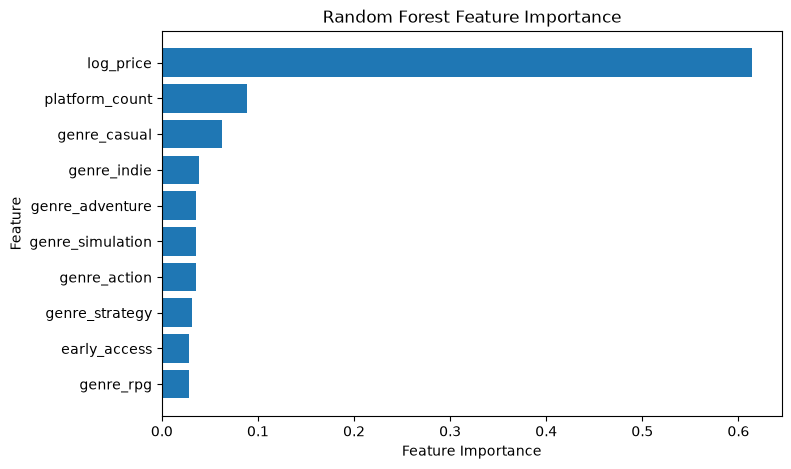

In [16]:
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.show()

## 6. Final Conclusion

This supervised-learning analysis tested whether product
and market-positioning characteristics could help identify
Steam games that reach at least 100,000 estimated owners.

The modeling sample contained 81,292 games with available
owner estimates. High-reach titles represented only 9.43%
of the sample, creating a strongly imbalanced classification
problem.

To avoid data leakage, the predictors were restricted to
product-positioning characteristics: price, desktop-platform
availability, major genres and Early Access status.

Performance variables such as reviews, satisfaction,
concurrent players and playtime were excluded.

Two models were compared. Logistic Regression provided an
interpretable baseline, while Random Forest was used to
capture nonlinear relationships and interactions between
features.

Random Forest achieved the stronger overall results, with
a ROC-AUC of 0.710, Average Precision of 0.239 and an
F1-score of 0.299 for the high-reach class.

Its precision for high-reach games was 20.1% and recall
was 58.6%.

The results show that product-positioning characteristics
contain useful predictive information, but they are not
sufficient to predict market reach with high precision.

This is consistent with the idea that commercial performance
also depends on important factors that are not captured in
the dataset, such as marketing, franchise strength, product
quality, timing and community dynamics.

Price was the most important feature in the Random Forest
model, but this should not be interpreted causally.
Feature importance indicates predictive usefulness within
the model, not that changing a feature will cause higher
reach.

Overall, the supervised model should be interpreted as an
exploratory decision-support tool rather than a success
predictor.

Combined with the market segmentation, it helps show where
a game sits in the Steam market, how comparable segments
perform, and whether its product characteristics resemble
games that historically achieved higher reach.